In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Path to the cleaned dataset from Task 1
file_path = Path(
    "../data/ApexPlanet_Cleaned_Sales_Dataset.xlsx"
)

# Load the dataset
df = pd.read_excel(file_path)

# Display the first five records
display(df.head())

,Transaction_ID,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,TXN000001,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,TXN000002,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,TXN000003,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,TXN000004,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,TXN000005,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset shape: (1000, 13)

Column names:
['Transaction_ID', 'Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Transaction_ID  1000 non-null   str           
 1   Order_ID        1000 non-null   str           
 2   Order_Date      1000 non-null   datetime64[us]
 3   Customer_ID     1000 non-null   str           
 4   Customer_Name   1000 non-null   str           
 5   Age             981 non-null    float64       
 6   Gender          1000 non-null   str           
 7   City            989 non-null    str           
 8   Product         1000 non-null   str           
 9   Category        1000 non-null   str           
 10  Quantity        1000 non-null   int64         


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Transaction_ID,1000,1000,TXN000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_ID,1000,992,ORD100050,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,1000,NaN,NaN,NaN,2025-07-03 11:19:40.800000,2025-01-01 00:00:00,2025-03-30 18:00:00,2025-07-01 00:00:00,2025-10-07 06:00:00,2026-01-01 00:00:00,NaN
Customer_ID,1000,947,CUST2515,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,1000,425,Customer_359,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,981.0,NaN,NaN,NaN,41.377166,18.0,30.0,41.0,54.0,65.0,13.825754
Gender,1000,2,Male,511,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,989,8,Patna,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1000,6,Mobile,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1000,5,Electronics,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Select numerical columns
numeric_cols = ["Age", "Quantity", "Unit_Price", "Total_Sales"]

# Generate descriptive statistics
display(df[numeric_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age,981.0,41.38,13.83,18.00,30.00,41.00,54.00,65.00
Quantity,1000.0,5.44,2.84,1.00,3.00,5.00,8.00,10.00
Unit_Price,1000.0,25486.78,14179.40,145.78,13895.72,25398.74,37512.38,49997.53
Total_Sales,1000.0,139399.44,114100.05,437.34,47066.63,108594.02,203722.88,493677.50


In [4]:
# Examine unique values and their frequencies
categorical_cols = [
    "Gender", "City", "Product", "Category"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(10))


--- Gender ---
Unique values: 2


Gender
Male      511
Female    489
Name: count, dtype: int64


--- City ---
Unique values: 8


City
Patna        136
Kolkata      133
Mumbai       131
Hyderabad    125
Delhi        125
Bengaluru    122
Gaya         118
Pune          99
NaN           11
Name: count, dtype: int64


--- Product ---
Unique values: 6


Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64


--- Category ---
Unique values: 5


Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64

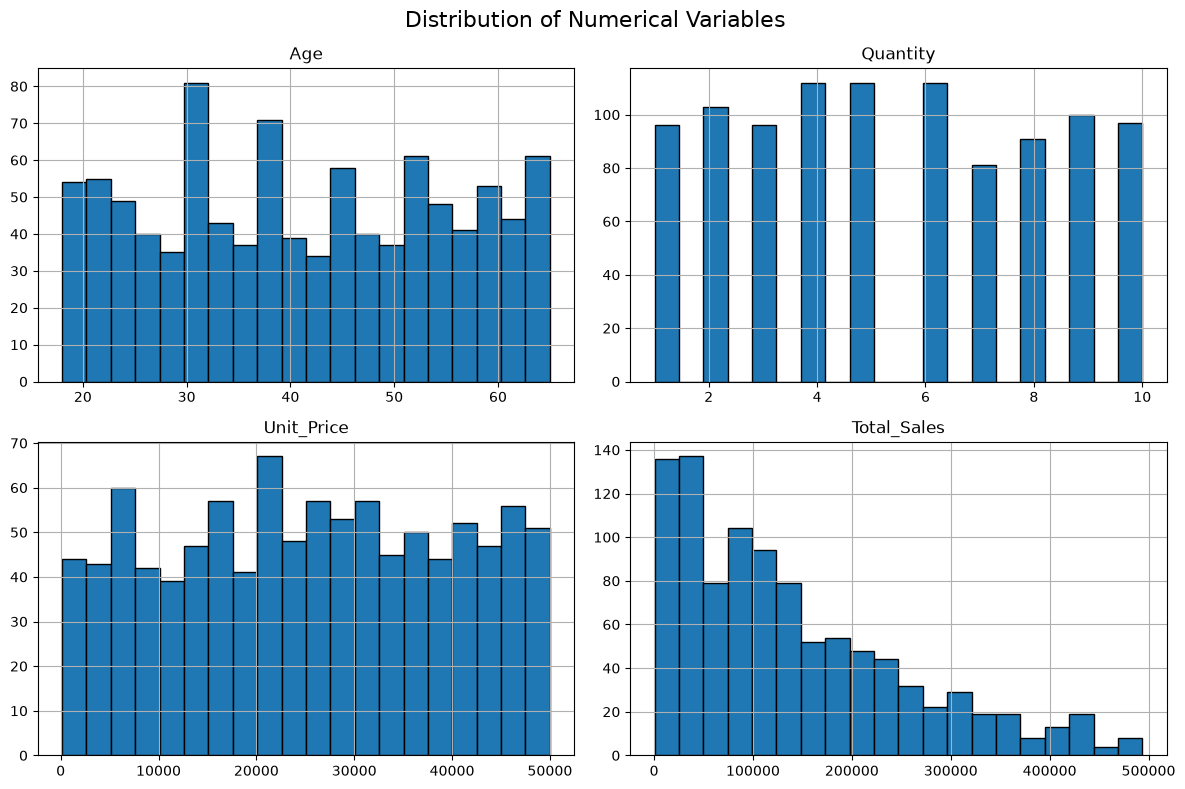

In [5]:
# Histograms
df[numeric_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

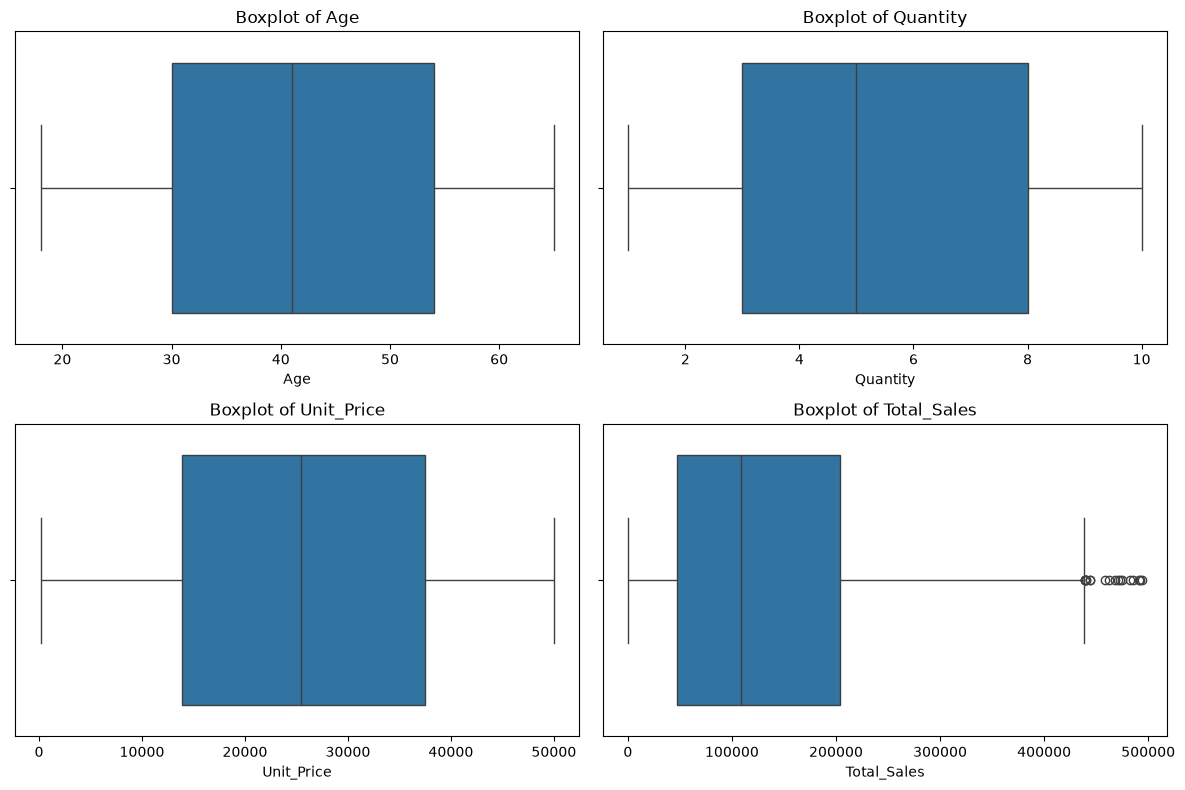

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(numeric_cols, axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [7]:
# Check sales calculation consistency
df["Calculated_Sales"] = df["Quantity"] * df["Unit_Price"]

df["Sales_Difference"] = (
    df["Total_Sales"] - df["Calculated_Sales"]
).round(2)

print("Records with inconsistent sales calculations:",
      (df["Sales_Difference"].abs() > 0.01).sum())

# Identify potential outliers using the IQR method
q1 = df["Total_Sales"].quantile(0.25)
q3 = df["Total_Sales"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[df["Total_Sales"] > upper_bound]

print("Lower IQR bound:", round(lower_bound, 2))
print("Upper IQR bound:", round(upper_bound, 2))
print("Potential high-sales outliers:", len(outliers))

display(
    outliers[
        ["Transaction_ID", "Product", "Category",
         "Quantity", "Unit_Price", "Total_Sales"]
    ].sort_values("Total_Sales", ascending=False).head(10)
)

# Remove the temporary validation columns
df.drop(
    columns=["Calculated_Sales", "Sales_Difference"],
    inplace=True
)

Records with inconsistent sales calculations: 0
Lower IQR bound: -187917.74
Upper IQR bound: 438707.26
Potential high-sales outliers: 19


,Transaction_ID,Product,Category,Quantity,Unit_Price,Total_Sales
50,TXN000051,Book,Education,10,49367.75,493677.5
762,TXN000763,Laptop,Electronics,10,49217.41,492174.1
220,TXN000221,Shoes,Fashion,10,49086.64,490866.4
972,TXN000973,Laptop,Electronics,10,48566.78,485667.8
622,TXN000623,Rice,Grocery,10,48255.19,482551.9
364,TXN000365,Mobile,Electronics,10,47493.59,474935.9
947,TXN000948,Book,Education,10,47314.42,473144.2
712,TXN000713,Mobile,Electronics,10,47079.86,470798.6
980,TXN000981,Rice,Grocery,10,46852.20,468522.0
656,TXN000657,Shoes,Fashion,10,46270.13,462701.3


In [8]:
# Category-wise business performance
category_sales = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Transaction_Count=("Transaction_ID", "nunique"),
        Average_Sale=("Total_Sales", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

category_sales["Sales_Percentage"] = (
    category_sales["Total_Sales"]
    / category_sales["Total_Sales"].sum()
    * 100
).round(2)

display(category_sales.round(2))

,Total_Sales,Total_Quantity,Transaction_Count,Average_Sale,Sales_Percentage
Category,,,,,
Electronics,50778581.70,1978,354,143442.32,36.43
Education,25031689.40,977,178,140627.47,17.96
Grocery,22231711.28,826,153,145305.30,15.95
Furniture,21521561.48,855,159,135355.73,15.44
Fashion,19835895.79,799,156,127153.18,14.23


In [9]:
# Product-wise business performance
product_sales = (
    df.groupby("Product")
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Transaction_Count=("Transaction_ID", "nunique"),
        Average_Sale=("Total_Sales", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(product_sales.round(2))

,Total_Sales,Total_Quantity,Transaction_Count,Average_Sale
Product,,,,
Laptop,25443008.51,970,170,149664.76
Mobile,25335573.19,1008,184,137693.33
Book,25031689.40,977,178,140627.47
Rice,22231711.28,826,153,145305.30
Chair,21521561.48,855,159,135355.73
Shoes,19835895.79,799,156,127153.18


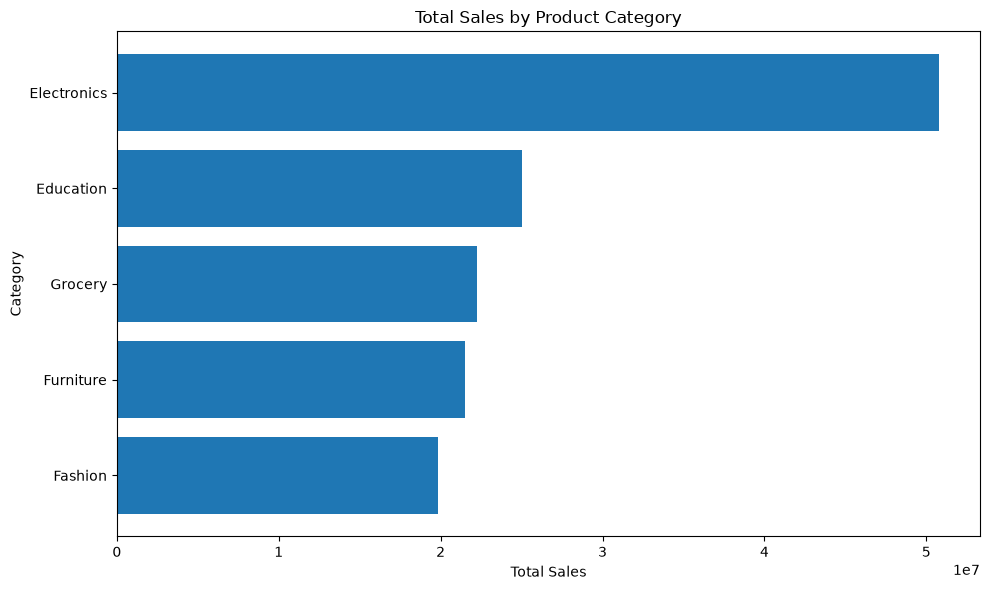

In [10]:
plt.figure(figsize=(10, 6))

category_sales_sorted = category_sales.sort_values("Total_Sales")

plt.barh(
    category_sales_sorted.index,
    category_sales_sorted["Total_Sales"]
)

plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(
    "../visualizations/sales_by_category.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


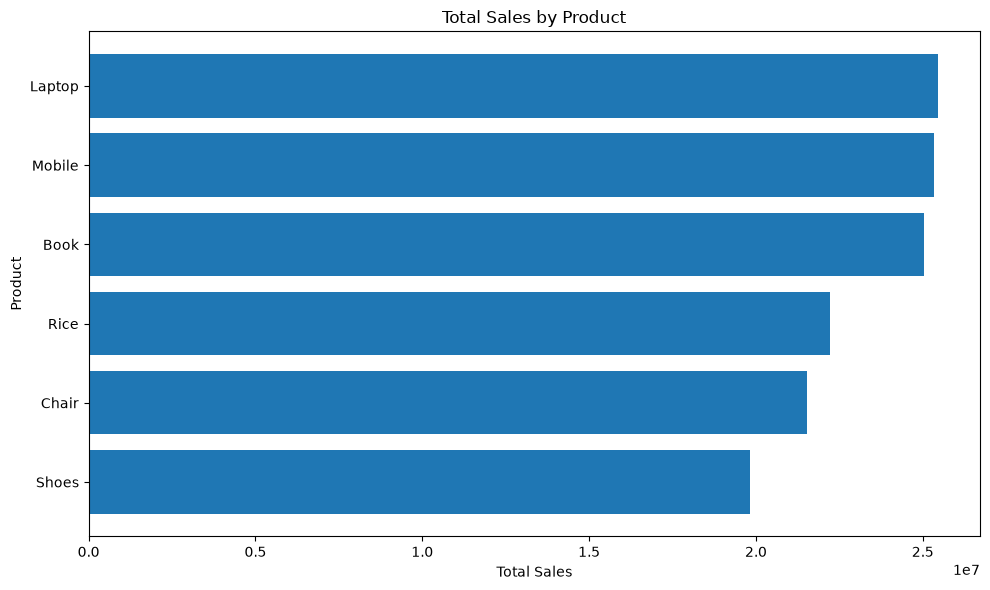

In [11]:
plt.figure(figsize=(10, 6))

product_sales_sorted = product_sales.sort_values("Total_Sales")

plt.barh(
    product_sales_sorted.index,
    product_sales_sorted["Total_Sales"]
)

plt.title("Total Sales by Product")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    "../visualizations/sales_by_product.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [12]:
# Ensure Order_Date is datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Extract month and year
df["Year_Month"] = df["Order_Date"].dt.to_period("M")

# Calculate monthly performance
monthly_sales = (
    df.groupby("Year_Month")
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Transactions=("Transaction_ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_index()
)

display(monthly_sales.round(2))

,Total_Sales,Transactions,Total_Quantity
Year_Month,,,
2025-01,10096190.73,76,376
2025-02,11511181.46,86,444
2025-03,13059899.94,89,467
2025-04,12222700.17,80,482
2025-05,10984689.25,85,424
2025-06,12912332.64,83,477
2025-07,11746226.80,83,466
2025-08,9448471.22,75,391
2025-09,9179896.29,79,406


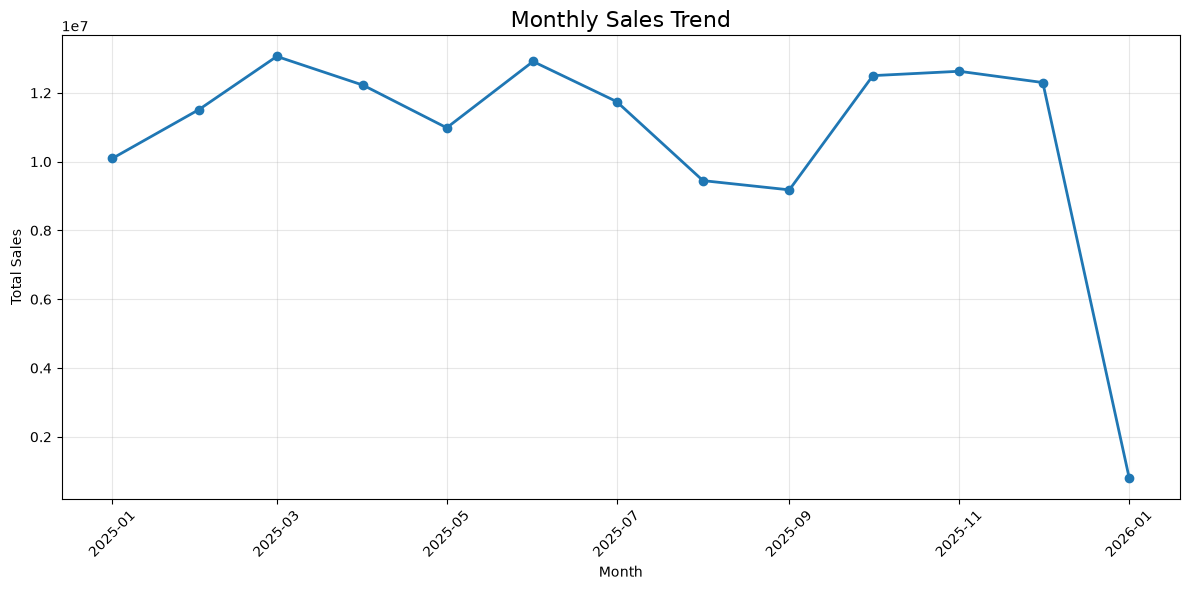

In [13]:
# Convert monthly periods to timestamps for plotting
plot_dates = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(
    plot_dates,
    monthly_sales["Total_Sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../visualizations/monthly_sales_trend.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [14]:
best_month = monthly_sales["Total_Sales"].idxmax()
worst_month = monthly_sales["Total_Sales"].idxmin()

print("Best month:", best_month)
print(
    "Highest monthly sales:",
    round(monthly_sales.loc[best_month, "Total_Sales"], 2)
)

print("\nLowest month:", worst_month)
print(
    "Lowest monthly sales:",
    round(monthly_sales.loc[worst_month, "Total_Sales"], 2)
)

Best month: 2025-03
Highest monthly sales: 13059899.94

Lowest month: 2026-01
Lowest monthly sales: 809389.99


In [15]:
# City-wise sales analysis
city_sales = (
    df.groupby("City")
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Transactions=("Transaction_ID", "nunique"),
        Average_Sale=("Total_Sales", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

city_sales["Sales_Percentage"] = (
    city_sales["Total_Sales"]
    / df["Total_Sales"].sum()
    * 100
)

display(city_sales.round(2))

print("Records with missing city:", df["City"].isna().sum())

,Total_Sales,Total_Quantity,Transactions,Average_Sale,Sales_Percentage
City,,,,,
Patna,19323101.85,759,136,142081.63,13.86
Kolkata,18884349.57,748,133,141987.59,13.55
Bengaluru,18773574.32,670,122,153881.76,13.47
Mumbai,18757050.17,707,131,143183.59,13.46
Hyderabad,17166766.87,669,125,137334.13,12.31
Delhi,16097079.00,662,125,128776.63,11.55
Gaya,14818939.99,619,118,125584.24,10.63
Pune,14513175.90,552,99,146597.74,10.41


Records with missing city: 11


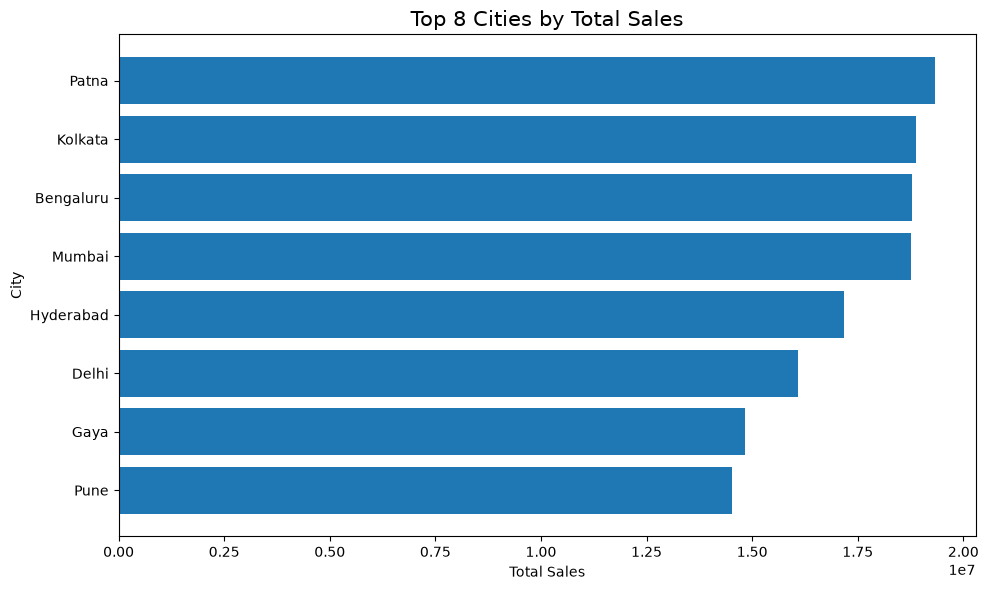

In [16]:
# Top 8 cities by total sales
top_cities = city_sales.head(8).sort_values("Total_Sales")

plt.figure(figsize=(10, 6))

plt.barh(
    top_cities.index,
    top_cities["Total_Sales"]
)

plt.title("Top 8 Cities by Total Sales", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.tight_layout()
plt.savefig(
    "../visualizations/sales_by_city.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [17]:
# Create age groups without modifying the original Age column
age_bins = [0, 25, 35, 45, 55, 100]
age_labels = [
    "18–25", "26–35", "36–45", "46–55", "56+"
]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_analysis = (
    df.groupby("Age_Group", observed=False)
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Transactions=("Transaction_ID", "nunique"),
        Average_Sale=("Total_Sales", "mean")
    )
)

display(age_analysis.round(2))

,Total_Sales,Transactions,Average_Sale
Age_Group,,,
18–25,22284096.94,158,141038.59
26–35,29632336.96,219,135307.47
36–45,28044649.24,203,138150.98
46–55,28216508.63,202,139685.69
56+,28171332.01,199,141564.48


,Age,Quantity,Unit_Price,Total_Sales
Age,1.00,-0.03,-0.01,0.00
Quantity,-0.03,1.00,0.02,0.65
Unit_Price,-0.01,0.02,1.00,0.69
Total_Sales,0.00,0.65,0.69,1.00


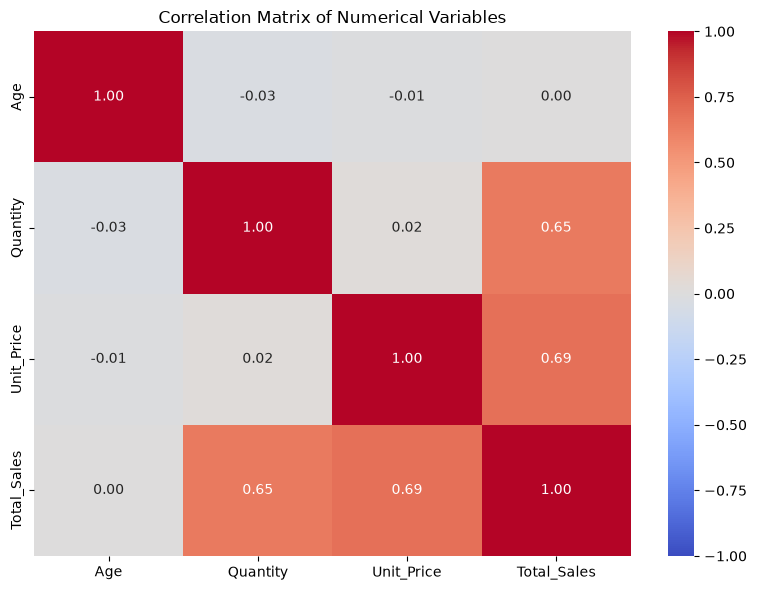

In [18]:
# Select numerical variables
analysis_cols = [
    "Age", "Quantity", "Unit_Price", "Total_Sales"
]

# Calculate correlation matrix
correlation_matrix = df[analysis_cols].corr()

display(correlation_matrix.round(2))

# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.savefig(
    "../visualizations/correlation_matrix.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


Gender,Female,Male
Category,,
Education,12844409.25,12187280.15
Electronics,22625505.63,28153076.07
Fashion,11545321.80,8290573.99
Furniture,10086833.91,11434727.57
Grocery,9833818.43,12397892.85


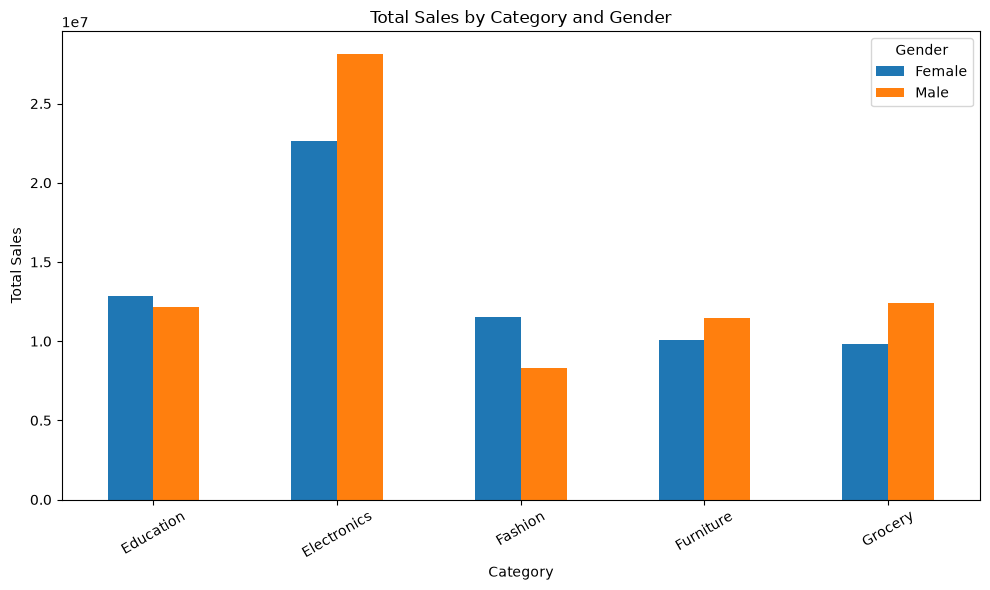

In [19]:
# Category-wise sales split by gender
category_gender_sales = pd.pivot_table(
    df,
    values="Total_Sales",
    index="Category",
    columns="Gender",
    aggfunc="sum",
    fill_value=0
)

display(category_gender_sales.round(2))

# Grouped bar chart
category_gender_sales.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Total Sales by Category and Gender")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

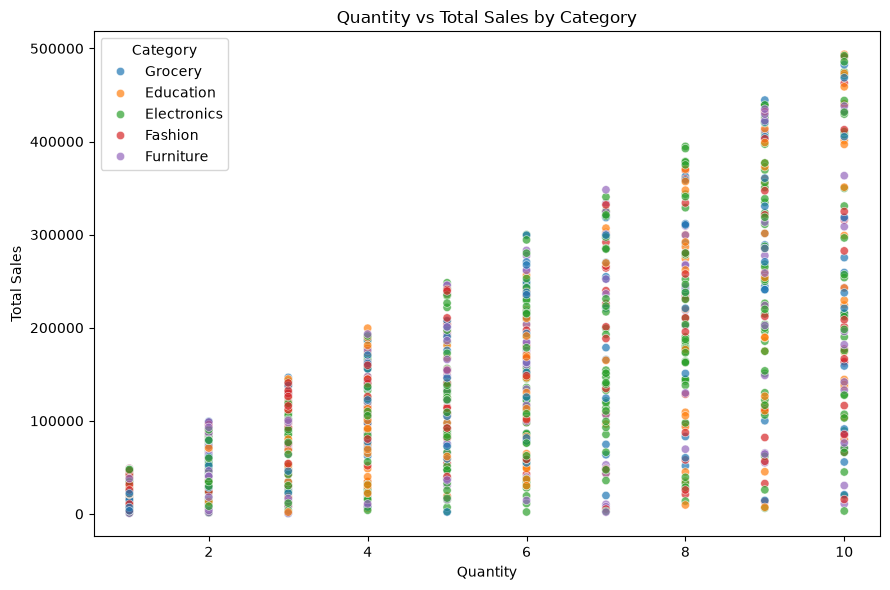

In [20]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total_Sales",
    hue="Category",
    alpha=0.7
)

plt.title("Quantity vs Total Sales by Category")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
from pathlib import Path

# Load the original cleaned Excel dataset
source_file = Path(
    "../data/ApexPlanet_Cleaned_Sales_Dataset.xlsx"
)

output_file = Path(
    "../data/ApexPlanet_Sales_NULL.csv"
)

df_export = pd.read_excel(source_file)

# Keep exactly the original 13 columns
columns = [
    "Transaction_ID",
    "Order_ID",
    "Order_Date",
    "Customer_ID",
    "Customer_Name",
    "Age",
    "Gender",
    "City",
    "Product",
    "Category",
    "Quantity",
    "Unit_Price",
    "Total_Sales"
]

df_export = df_export[columns].copy()

# Format dates consistently
df_export["Order_Date"] = pd.to_datetime(
    df_export["Order_Date"],
    errors="coerce"
).dt.strftime("%Y-%m-%d %H:%M:%S")

# Verify that non-missing ages are whole numbers
ages = pd.to_numeric(df_export["Age"], errors="coerce")
valid_ages = ages.dropna()

if not (valid_ages % 1 == 0).all():
    raise ValueError("Some ages are not whole numbers.")

# Convert Age to a nullable integer type
df_export["Age"] = ages.astype("Int64")

# Format numeric values consistently
df_export["Quantity"] = pd.to_numeric(
    df_export["Quantity"], errors="raise"
).astype("Int64")

for col in ["Unit_Price", "Total_Sales"]:
    df_export[col] = pd.to_numeric(
        df_export[col], errors="raise"
    ).round(2)

# Export missing values as the literal text NULL
df_export.to_csv(
    output_file,
    index=False,
    encoding="utf-8",
    na_rep="NULL"
)

# Verify the exported dataset
print("CSV file:", output_file.resolve())
print("Rows:", len(df_export))
print("Columns:", len(df_export.columns))
print("Missing ages:", df_export["Age"].isna().sum())
print("Missing cities:", df_export["City"].isna().sum())

# Display rows containing missing values
display(
    df_export[
        df_export["Age"].isna() | df_export["City"].isna()
    ]
)

CSV file: C:\Users\bhanu\Downloads\ApexPlanet-Data-Analytics-Internship\ApexPlanet-Data-Analytics-Internship\02_Task_2_EDA_SQL\data\ApexPlanet_Sales_NULL.csv
Rows: 1000
Columns: 13
Missing ages: 19
Missing cities: 11


,Transaction_ID,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
48,TXN000049,ORD100050,2025-10-03 00:00:00,CUST5523,Customer_432,<NA>,Male,Pune,Chair,Furniture,9,30834.87,277513.83
73,TXN000074,ORD100075,2025-03-30 00:00:00,CUST2157,Customer_31,58,Male,NaN,Mobile,Electronics,4,21599.26,86397.04
98,TXN000099,ORD100100,2025-11-02 00:00:00,CUST7462,Customer_379,<NA>,Male,Patna,Laptop,Electronics,5,553.62,2768.10
148,TXN000149,ORD100150,2025-04-01 00:00:00,CUST4132,Customer_47,<NA>,Female,NaN,Chair,Furniture,4,1973.64,7894.56
198,TXN000199,ORD100200,2025-02-24 00:00:00,CUST2953,Customer_435,<NA>,Female,Kolkata,Rice,Grocery,8,27608.55,220868.40
223,TXN000224,ORD100225,2025-12-07 00:00:00,CUST1443,Customer_315,37,Female,NaN,Rice,Grocery,1,25336.70,25336.70
248,TXN000249,ORD100250,2025-12-20 00:00:00,CUST3169,Customer_138,<NA>,Female,Delhi,Mobile,Electronics,7,19829.73,138808.11
298,TXN000299,ORD100300,2025-07-01 00:00:00,CUST7944,Customer_282,<NA>,Male,NaN,Chair,Furniture,6,28595.31,171571.86
348,TXN000349,ORD100350,2025-07-11 00:00:00,CUST9709,Customer_409,<NA>,Male,Pune,Laptop,Electronics,8,47254.70,378037.60
373,TXN000374,ORD100375,2025-05-06 00:00:00,CUST5835,Customer_362,20,Male,NaN,Laptop,Electronics,2,28311.58,56623.16


In [22]:
import pandas as pd
from pathlib import Path

# Load the original cleaned dataset
data_path = Path("../data")
source_file = data_path / "ApexPlanet_Cleaned_Sales_Dataset.xlsx"

df = pd.read_excel(source_file)

# Preserve the original 13-column structure
columns = [
    "Transaction_ID", "Order_ID", "Order_Date",
    "Customer_ID", "Customer_Name", "Age", "Gender",
    "City", "Product", "Category", "Quantity",
    "Unit_Price", "Total_Sales"
]
df = df[columns].copy()

# Identify rows with missing ages and cities BEFORE filling
missing_age = df["Age"].isna()
missing_city = df["City"].isna()

# Save a record of the original missing values
missing_records = df.loc[
    missing_age | missing_city,
    ["Transaction_ID", "Age", "City"]
].copy()

missing_records["Age_Was_Missing"] = missing_age[missing_age | missing_city].values
missing_records["City_Was_Missing"] = missing_city[missing_age | missing_city].values

missing_records.to_csv(
    data_path / "Missing_Values_Transactions.csv",
    index=False,
    na_rep="NULL"
)

# Fill missing ages with the rounded median age
age_median = int(round(df["Age"].median()))
df["Age"] = df["Age"].fillna(age_median).astype(int)

# Fill missing cities with a temporary placeholder
df["City"] = df["City"].fillna("Unknown")

# Format dates for MySQL
df["Order_Date"] = pd.to_datetime(df["Order_Date"]).dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)

# Export the temporary import file
df.to_csv(
    data_path / "ApexPlanet_Sales_Import.csv",
    index=False,
    encoding="utf-8"
)

# Generate SQL to restore the originally missing values
sql_lines = [
    "USE apexplanet_task2;",
    "",
    "-- Restore values that were originally missing in the source dataset."
]

for _, row in missing_records.iterrows():
    transaction_id = row["Transaction_ID"].replace("'", "''")

    if row["Age_Was_Missing"]:
        sql_lines.append(
            f"UPDATE sales_reimport SET Age = NULL "
            f"WHERE Transaction_ID = '{transaction_id}';"
        )

    if row["City_Was_Missing"]:
        sql_lines.append(
            f"UPDATE sales_reimport SET City = NULL "
            f"WHERE Transaction_ID = '{transaction_id}';"
        )

(data_path / "Restore_Missing_Values.sql").write_text(
    "\n".join(sql_lines) + "\n",
    encoding="utf-8"
)

# Confirm the generated import file is complete
print("Original rows:", len(pd.read_excel(source_file)))
print("Import rows:", len(df))
print("Missing ages originally:", missing_age.sum())
print("Missing cities originally:", missing_city.sum())
print("Temporary age replacement:", age_median)
print("Temporary city replacement: Unknown")
print("Files created successfully.")

Original rows: 1000
Import rows: 1000
Missing ages originally: 19
Missing cities originally: 11
Temporary age replacement: 41
Temporary city replacement: Unknown
Files created successfully.


In [23]:

from pathlib import Path
from PIL import Image
import numpy as np

visual_dir = Path("visualizations")

for file in sorted(visual_dir.glob("*.png")):
    image = np.array(Image.open(file).convert("RGB"))

    print(
        f"{file.name}: "
        f"size={Image.open(file).size}, "
        f"unique_colors={len(np.unique(image.reshape(-1, 3), axis=0))}, "
        f"min_pixel={image.min()}, "
        f"max_pixel={image.max()}"
    )


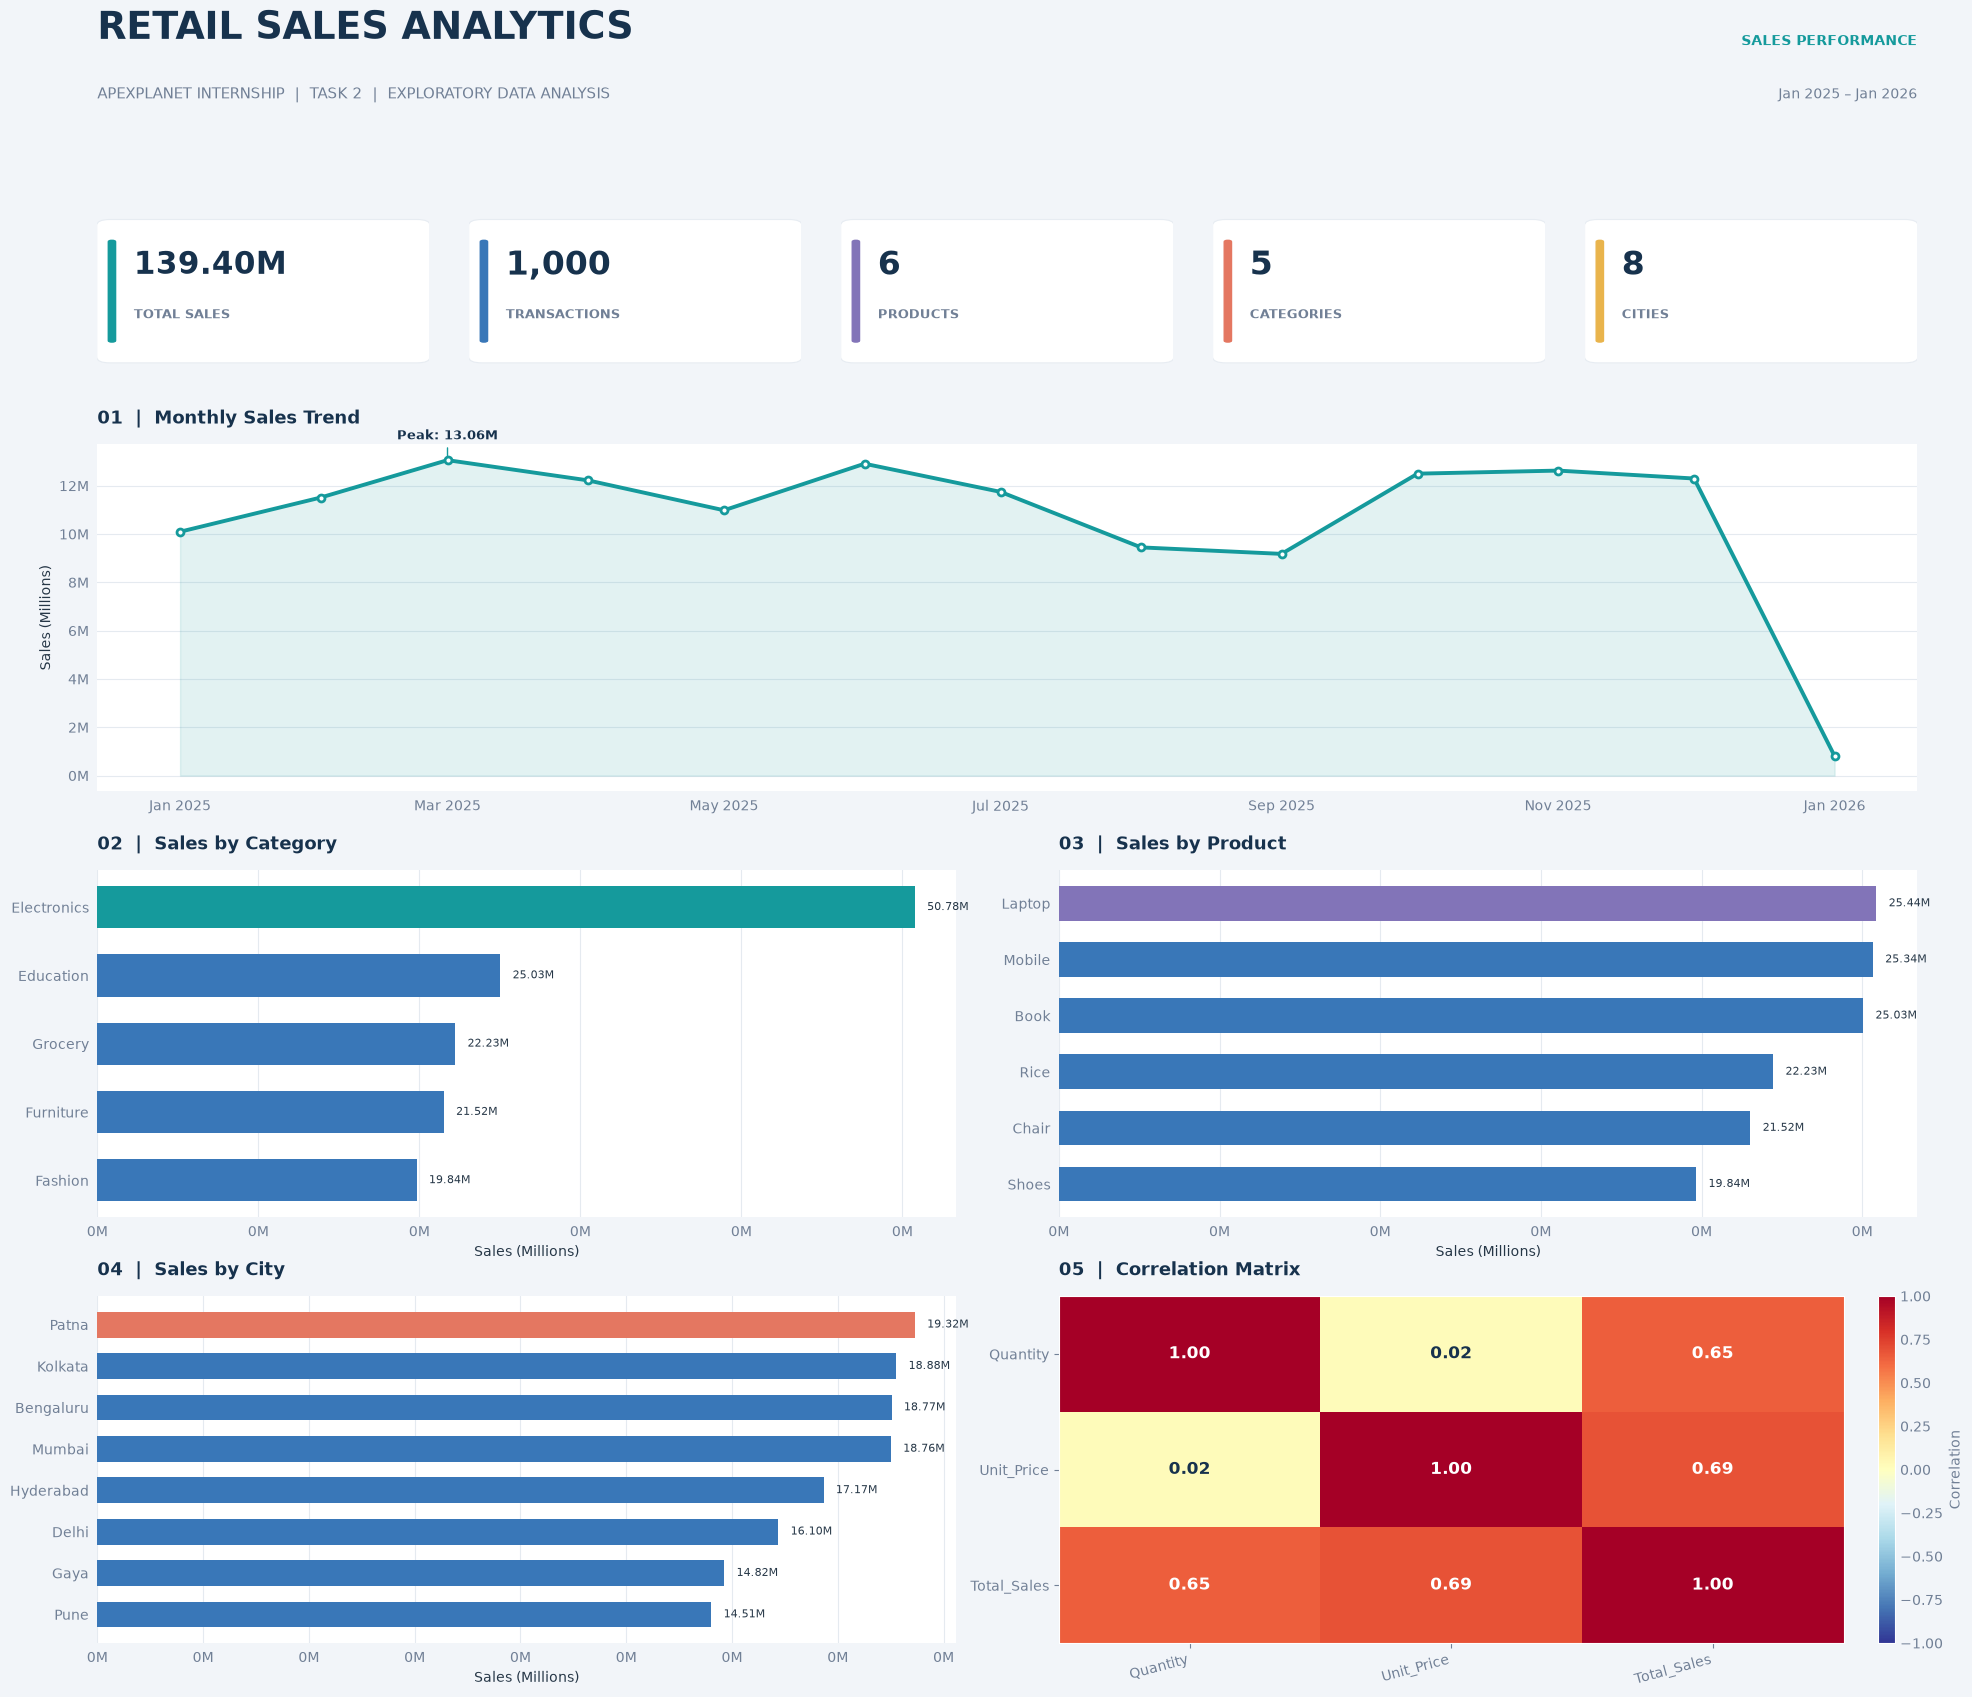


Dashboard created successfully!
Total sales: 139,399,439.65
Transactions: 1,000
Dashboard saved to: c:\Users\bhanu\Downloads\ApexPlanet-Data-Analytics-Internship\ApexPlanet-Data-Analytics-Internship\02_Task_2_EDA_SQL\dashboard\retail_sales_dashboard.png


In [24]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import FancyBboxPatch
from matplotlib.gridspec import GridSpec


# ============================================================
# 1. CONFIGURATION AND COLOR PALETTE
# ============================================================

NAVY = "#17324D"
TEAL = "#159A9C"
BLUE = "#3977B8"
GOLD = "#E9B44C"
CORAL = "#E47761"
PURPLE = "#8274B8"

BG = "#F2F5F9"
WHITE = "#FFFFFF"
TEXT = "#263747"
MUTED = "#718096"
GRID = "#E5EAF0"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelcolor": TEXT,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": TEXT,
    "figure.facecolor": BG,
    "axes.facecolor": WHITE,
    "axes.edgecolor": WHITE,
    "savefig.facecolor": BG,
})


# ============================================================
# 2. FIND AND LOAD THE CLEANED DATASET
# ============================================================

project_dir = Path.cwd()

if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent

possible_files = [
    project_dir / "data" / "ApexPlanet_Cleaned_Sales_Dataset.xlsx",
    project_dir / "ApexPlanet_Cleaned_Sales_Dataset.xlsx",
    project_dir / "ApexPlanet_Cleaned_Sales_Dataset.csv",
    project_dir / "data" / "ApexPlanet_Cleaned_Sales_Dataset.csv",
]

data_file = next(
    (path for path in possible_files if path.exists()),
    None
)

if data_file is None:
    raise FileNotFoundError(
        "Cleaned dataset not found. Update possible_files with "
        "the correct location of your Excel or CSV file."
    )

if data_file.suffix.lower() == ".csv":
    df = pd.read_csv(data_file)
else:
    df = pd.read_excel(data_file)

required_columns = [
    "Transaction_ID",
    "Order_Date",
    "City",
    "Product",
    "Category",
    "Quantity",
    "Unit_Price",
    "Total_Sales",
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

for col in ["Quantity", "Unit_Price", "Total_Sales"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Order_Date", "Total_Sales"])

output_dir = project_dir / "dashboard"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "retail_sales_dashboard.png"


# ============================================================
# 3. CALCULATE KPI VALUES
# ============================================================

total_sales = df["Total_Sales"].sum()
transactions = df["Transaction_ID"].nunique()
products = df["Product"].nunique()
categories = df["Category"].nunique()
cities = df["City"].nunique()

kpis = [
    ("TOTAL SALES", f"{total_sales / 1_000_000:.2f}M", TEAL),
    ("TRANSACTIONS", f"{transactions:,}", BLUE),
    ("PRODUCTS", f"{products:,}", PURPLE),
    ("CATEGORIES", f"{categories:,}", CORAL),
    ("CITIES", f"{cities:,}", GOLD),
]


# ============================================================
# 4. PREPARE CHART DATA
# ============================================================

monthly_sales = (
    df.set_index("Order_Date")["Total_Sales"]
      .resample("MS")
      .sum()
      .reset_index()
)

category_sales = (
    df.groupby("Category", dropna=False)["Total_Sales"]
      .sum()
      .sort_values()
)

product_sales = (
    df.groupby("Product", dropna=False)["Total_Sales"]
      .sum()
      .sort_values()
)

city_sales = (
    df.dropna(subset=["City"])
      .groupby("City")["Total_Sales"]
      .sum()
      .sort_values()
)

correlation_data = df[
    ["Quantity", "Unit_Price", "Total_Sales"]
].corr()

# Format sales axes in millions for readability.
def millions_formatter(value, _position):
    return f"{value / 1_000_000:.0f}M"


# Consistent styling for chart panels.
def style_axis(ax, title):
    ax.set_facecolor(WHITE)
    ax.set_title(title, loc="left", color=NAVY, pad=15)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(length=0, pad=6)


# ============================================================
# 5. CREATE THE DASHBOARD LAYOUT
# ============================================================

fig = plt.figure(figsize=(20, 15), facecolor=BG)

outer = GridSpec(
    4, 1,
    figure=fig,
    height_ratios=[0.75, 1.0, 2.4, 2.4],
    hspace=0.32,
    left=0.055,
    right=0.965,
    top=0.95,
    bottom=0.055,
)

# ============================================================
# 6. HEADER
# ============================================================

header_ax = fig.add_subplot(outer[0])
header_ax.axis("off")

header_ax.text(
    0.0, 0.80,
    "RETAIL SALES ANALYTICS",
    fontsize=27,
    fontweight="bold",
    color=NAVY,
    transform=header_ax.transAxes,
)

header_ax.text(
    0.0, 0.35,
    "APEXPLANET INTERNSHIP  |  TASK 2  |  EXPLORATORY DATA ANALYSIS",
    fontsize=11,
    color=MUTED,
    transform=header_ax.transAxes,
)

header_ax.text(
    1.0, 0.77,
    "SALES PERFORMANCE",
    fontsize=10,
    fontweight="bold",
    color=TEAL,
    ha="right",
    transform=header_ax.transAxes,
)

header_ax.text(
    1.0, 0.38,
    f"{df['Order_Date'].min():%b %Y} – {df['Order_Date'].max():%b %Y}",
    fontsize=10,
    color=MUTED,
    ha="right",
    transform=header_ax.transAxes,
)


# ============================================================
# 7. KPI CARDS
# ============================================================

kpi_grid = outer[1].subgridspec(
    1, 5,
    wspace=0.12,
)

for i, (label, value, accent) in enumerate(kpis):
    ax = fig.add_subplot(kpi_grid[0, i])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Rounded white card with a colored accent strip.
    card = FancyBboxPatch(
        (0.01, 0.03), 0.98, 0.94,
        boxstyle="round,pad=0.012,rounding_size=0.04",
        facecolor=WHITE,
        edgecolor="#E7ECF2",
        linewidth=0.8,
        transform=ax.transAxes,
        clip_on=False,
    )
    ax.add_patch(card)

    ax.add_patch(
        FancyBboxPatch(
            (0.035, 0.16), 0.018, 0.68,
            boxstyle="round,pad=0.002,rounding_size=0.01",
            facecolor=accent,
            edgecolor=accent,
            transform=ax.transAxes,
        )
    )

    ax.text(
        0.11, 0.67,
        value,
        fontsize=23 if i == 0 else 24,
        fontweight="bold",
        color=NAVY,
        va="center",
        transform=ax.transAxes,
    )

    ax.text(
        0.11, 0.34,
        label,
        fontsize=9,
        fontweight="bold",
        color=MUTED,
        va="center",
        transform=ax.transAxes,
    )


# ============================================================
# 8. MONTHLY SALES TREND
# ============================================================

monthly_ax = fig.add_subplot(outer[2])
style_axis(monthly_ax, "01  |  Monthly Sales Trend")

monthly_ax.plot(
    monthly_sales["Order_Date"],
    monthly_sales["Total_Sales"] / 1_000_000,
    color=TEAL,
    linewidth=2.8,
    marker="o",
    markersize=6,
    markerfacecolor=WHITE,
    markeredgewidth=2,
    markeredgecolor=TEAL,
    zorder=3,
)

monthly_ax.fill_between(
    monthly_sales["Order_Date"],
    monthly_sales["Total_Sales"] / 1_000_000,
    color=TEAL,
    alpha=0.12,
)

monthly_ax.set_ylabel("Sales (Millions)")
monthly_ax.set_xlabel("Order Month")
monthly_ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
monthly_ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=4, maxticks=10)
)
monthly_ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0f}M")
)
monthly_ax.tick_params(axis="x", rotation=0)

if not monthly_sales.empty:
    peak_idx = monthly_sales["Total_Sales"].idxmax()
    peak = monthly_sales.loc[peak_idx]

    monthly_ax.annotate(
        f"Peak: {peak['Total_Sales'] / 1_000_000:.2f}M",
        xy=(
            peak["Order_Date"],
            peak["Total_Sales"] / 1_000_000,
        ),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=NAVY,
        arrowprops=dict(
            arrowstyle="-",
            color=TEAL,
            linewidth=1.2,
        ),
    )


# ============================================================
# 9. SALES BY CATEGORY
# ============================================================

middle_grid = outer[3].subgridspec(
    1, 2,
    wspace=0.12,
)

category_ax = fig.add_subplot(middle_grid[0, 0])
style_axis(category_ax, "02  |  Sales by Category")

category_colors = [
    TEAL if i == len(category_sales) - 1 else BLUE
    for i in range(len(category_sales))
]

bars = category_ax.barh(
    category_sales.index.astype(str),
    category_sales.values / 1_000_000,
    color=category_colors,
    height=0.62,
)

category_ax.set_xlabel("Sales (Millions)")
category_ax.set_ylabel("")
category_ax.xaxis.set_major_formatter(
    plt.FuncFormatter(millions_formatter)
)

for bar, value in zip(bars, category_sales.values):
    category_ax.text(
        bar.get_width() + max(category_sales.max() / 1_000_000 * 0.012, 0.1),
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center",
        fontsize=9,
        color=TEXT,
    )

category_ax.grid(axis="x", color=GRID, linewidth=0.8)
category_ax.grid(axis="y", visible=False)


# ============================================================
# 10. SALES BY PRODUCT
# ============================================================

product_ax = fig.add_subplot(middle_grid[0, 1])
style_axis(product_ax, "03  |  Sales by Product")

product_colors = [
    PURPLE if i == len(product_sales) - 1 else BLUE
    for i in range(len(product_sales))
]

bars = product_ax.barh(
    product_sales.index.astype(str),
    product_sales.values / 1_000_000,
    color=product_colors,
    height=0.62,
)

product_ax.set_xlabel("Sales (Millions)")
product_ax.set_ylabel("")
product_ax.xaxis.set_major_formatter(
    plt.FuncFormatter(millions_formatter)
)

for bar, value in zip(bars, product_sales.values):
    product_ax.text(
        bar.get_width() + max(product_sales.max() / 1_000_000 * 0.012, 0.1),
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center",
        fontsize=9,
        color=TEXT,
    )

product_ax.grid(axis="x", color=GRID, linewidth=0.8)
product_ax.grid(axis="y", visible=False)


# ============================================================
# 11. ADD A SECOND ROW FOR CITY SALES AND CORRELATION
# ============================================================

# Rebuild the bottom portion with a dedicated two-chart row.
# The outer layout above currently has one row for the two charts.
# To keep all five charts, split that area into two rows.

# Replace the overall layout with a 5-row layout for all charts.
# This is handled by creating a new figure below so every panel
# has enough space and the charts remain readable.

plt.close(fig)

fig = plt.figure(figsize=(20, 18), facecolor=BG)

outer = GridSpec(
    5, 1,
    figure=fig,
    height_ratios=[0.75, 0.9, 2.1, 2.1, 2.1],
    hspace=0.30,
    left=0.055,
    right=0.965,
    top=0.95,
    bottom=0.045,
)

# Header
header_ax = fig.add_subplot(outer[0])
header_ax.axis("off")
header_ax.text(
    0, 0.80, "RETAIL SALES ANALYTICS",
    fontsize=27, fontweight="bold", color=NAVY,
    transform=header_ax.transAxes,
)
header_ax.text(
    0, 0.32,
    "APEXPLANET INTERNSHIP  |  TASK 2  |  EXPLORATORY DATA ANALYSIS",
    fontsize=11, color=MUTED, transform=header_ax.transAxes,
)
header_ax.text(
    1, 0.75, "SALES PERFORMANCE",
    fontsize=10, fontweight="bold", color=TEAL,
    ha="right", transform=header_ax.transAxes,
)
header_ax.text(
    1, 0.32,
    f"{df['Order_Date'].min():%b %Y} – {df['Order_Date'].max():%b %Y}",
    fontsize=10, color=MUTED, ha="right",
    transform=header_ax.transAxes,
)

# KPI cards
kpi_grid = outer[1].subgridspec(1, 5, wspace=0.12)

for i, (label, value, accent) in enumerate(kpis):
    ax = fig.add_subplot(kpi_grid[0, i])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.add_patch(FancyBboxPatch(
        (0.01, 0.03), 0.98, 0.94,
        boxstyle="round,pad=0.012,rounding_size=0.04",
        facecolor=WHITE, edgecolor="#E7ECF2", linewidth=0.8,
        transform=ax.transAxes,
    ))
    ax.add_patch(FancyBboxPatch(
        (0.035, 0.16), 0.018, 0.68,
        boxstyle="round,pad=0.002,rounding_size=0.01",
        facecolor=accent, edgecolor=accent,
        transform=ax.transAxes,
    ))
    ax.text(
        0.11, 0.67, value,
        fontsize=22 if i == 0 else 24,
        fontweight="bold", color=NAVY,
        va="center", transform=ax.transAxes,
    )
    ax.text(
        0.11, 0.34, label,
        fontsize=9, fontweight="bold", color=MUTED,
        va="center", transform=ax.transAxes,
    )

# Monthly sales trend
monthly_ax = fig.add_subplot(outer[2])
style_axis(monthly_ax, "01  |  Monthly Sales Trend")
monthly_ax.plot(
    monthly_sales["Order_Date"],
    monthly_sales["Total_Sales"] / 1_000_000,
    color=TEAL, linewidth=2.8, marker="o",
    markersize=5, markerfacecolor=WHITE,
    markeredgewidth=2, markeredgecolor=TEAL,
)
monthly_ax.fill_between(
    monthly_sales["Order_Date"],
    monthly_sales["Total_Sales"] / 1_000_000,
    color=TEAL, alpha=0.12,
)
monthly_ax.set_ylabel("Sales (Millions)")
monthly_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
monthly_ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=4, maxticks=10)
)
monthly_ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0f}M")
)

if not monthly_sales.empty:
    peak = monthly_sales.loc[monthly_sales["Total_Sales"].idxmax()]
    monthly_ax.annotate(
        f"Peak: {peak['Total_Sales'] / 1_000_000:.2f}M",
        xy=(peak["Order_Date"], peak["Total_Sales"] / 1_000_000),
        xytext=(0, 15), textcoords="offset points",
        ha="center", fontsize=9, fontweight="bold", color=NAVY,
        arrowprops=dict(arrowstyle="-", color=TEAL),
    )

# Category and product charts
sales_grid = outer[3].subgridspec(1, 2, wspace=0.12)

category_ax = fig.add_subplot(sales_grid[0, 0])
style_axis(category_ax, "02  |  Sales by Category")
bars = category_ax.barh(
    category_sales.index.astype(str),
    category_sales.values / 1_000_000,
    color=[BLUE] * max(len(category_sales) - 1, 0) + [TEAL],
    height=0.62,
)
category_ax.set_xlabel("Sales (Millions)")
category_ax.xaxis.set_major_formatter(
    plt.FuncFormatter(millions_formatter)
)
for bar, value in zip(bars, category_sales.values):
    category_ax.text(
        bar.get_width() + max(category_sales.max() / 1_000_000 * 0.015, 0.1),
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center", fontsize=8, color=TEXT,
    )
category_ax.grid(axis="x", color=GRID)
category_ax.grid(axis="y", visible=False)

product_ax = fig.add_subplot(sales_grid[0, 1])
style_axis(product_ax, "03  |  Sales by Product")
bars = product_ax.barh(
    product_sales.index.astype(str),
    product_sales.values / 1_000_000,
    color=[BLUE] * max(len(product_sales) - 1, 0) + [PURPLE],
    height=0.62,
)
product_ax.set_xlabel("Sales (Millions)")
product_ax.xaxis.set_major_formatter(
    plt.FuncFormatter(millions_formatter)
)
for bar, value in zip(bars, product_sales.values):
    product_ax.text(
        bar.get_width() + max(product_sales.max() / 1_000_000 * 0.015, 0.1),
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center", fontsize=8, color=TEXT,
    )
product_ax.grid(axis="x", color=GRID)
product_ax.grid(axis="y", visible=False)

# City sales and correlation matrix
bottom_grid = outer[4].subgridspec(1, 2, wspace=0.12)

city_ax = fig.add_subplot(bottom_grid[0, 0])
style_axis(city_ax, "04  |  Sales by City")
bars = city_ax.barh(
    city_sales.index.astype(str),
    city_sales.values / 1_000_000,
    color=[BLUE] * max(len(city_sales) - 1, 0) + [CORAL],
    height=0.62,
)
city_ax.set_xlabel("Sales (Millions)")
city_ax.xaxis.set_major_formatter(
    plt.FuncFormatter(millions_formatter)
)
for bar, value in zip(bars, city_sales.values):
    city_ax.text(
        bar.get_width() + max(city_sales.max() / 1_000_000 * 0.015, 0.1),
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center", fontsize=8, color=TEXT,
    )
city_ax.grid(axis="x", color=GRID)
city_ax.grid(axis="y", visible=False)

corr_ax = fig.add_subplot(bottom_grid[0, 1])
corr_ax.set_facecolor(WHITE)
corr_ax.set_title(
    "05  |  Correlation Matrix",
    loc="left", color=NAVY, pad=15,
)

corr_values = correlation_data.values
im = corr_ax.imshow(
    corr_values,
    cmap="RdYlBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto",
)

corr_labels = correlation_data.columns.tolist()
corr_ax.set_xticks(range(len(corr_labels)))
corr_ax.set_yticks(range(len(corr_labels)))
corr_ax.set_xticklabels(corr_labels, rotation=15, ha="right")
corr_ax.set_yticklabels(corr_labels)

for i in range(len(corr_labels)):
    for j in range(len(corr_labels)):
        val = corr_values[i, j]
        corr_ax.text(
            j, i, f"{val:.2f}",
            ha="center", va="center",
            fontsize=12, fontweight="bold",
            color="white" if abs(val) > 0.60 else NAVY,
        )

colorbar = fig.colorbar(
    im, ax=corr_ax, fraction=0.046, pad=0.04
)
colorbar.set_label("Correlation", color=MUTED)
colorbar.ax.tick_params(colors=MUTED, length=0)

# ============================================================
# 12. SAVE AND DISPLAY
# ============================================================

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=BG,
)

plt.show()

print("\nDashboard created successfully!")
print(f"Total sales: {total_sales:,.2f}")
print(f"Transactions: {transactions:,}")
print(f"Dashboard saved to: {output_file}")


In [25]:

from pathlib import Path
from PIL import Image
import numpy as np

# Locate the Task 2 project folder
project_dir = Path.cwd()

if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent

visual_dir = project_dir / "visualizations"

png_files = [
    "monthly_sales_trend.png",
    "sales_by_category.png",
    "sales_by_product.png",
    "sales_by_city.png",
    "correlation_matrix.png",
]

print("PNG Validation Results")
print("=" * 55)

for filename in png_files:
    path = visual_dir / filename

    if not path.exists():
        print(f"FAIL: {filename} — File not found")
        continue

    with Image.open(path) as img:
        img.load()
        pixels = np.asarray(img.convert("RGB"))

        is_valid = (
            img.width > 100
            and img.height > 100
            and pixels.std() > 5
        )

        status = "PASS" if is_valid else "CHECK"

        print(
            f"{status}: {filename} | "
            f"Size: {img.width} x {img.height} | "
            f"Pixel variation: {pixels.std():.2f}"
        )

print("=" * 55)


PNG Validation Results
PASS: monthly_sales_trend.png | Size: 3570 x 1769 | Pixel variation: 26.79
PASS: sales_by_category.png | Size: 2967 x 1768 | Pixel variation: 76.35
PASS: sales_by_product.png | Size: 2967 x 1768 | Pixel variation: 85.68
PASS: sales_by_city.png | Size: 2961 x 1769 | Pixel variation: 85.26
PASS: correlation_matrix.png | Size: 2270 x 1768 | Pixel variation: 78.46


In [26]:

from pathlib import Path
from PIL import Image
import numpy as np

# Locate the Task 2 project directory.
project_dir = Path.cwd()

# If the notebook runs from the notebooks folder, move up one level.
if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent

# Define the path to the final dashboard image.
dashboard_path = (
    project_dir / "dashboard" / "retail_sales_dashboard.png"
)

# Check whether the dashboard was generated.
if not dashboard_path.exists():
    print("FAIL: Dashboard image not found.")
    print("Expected location:", dashboard_path)

else:
    # Open the image and load its pixel data.
    with Image.open(dashboard_path) as img:
        img.load()
        pixels = np.asarray(img.convert("RGB"))

        # Check image dimensions and whether the image contains variation.
        dimensions_ok = img.width >= 1000 and img.height >= 700
        image_not_blank = pixels.std() > 5

        print("DASHBOARD VALIDATION")
        print("=" * 45)
        print("File:", dashboard_path.name)
        print(f"Dimensions: {img.width} x {img.height}")
        print(f"Pixel variation: {pixels.std():.2f}")
        print("Dimensions check:", "PASS" if dimensions_ok else "CHECK")
        print("Blank image check:", "PASS" if image_not_blank else "CHECK")

        # Report the overall result of these basic technical checks.
        if dimensions_ok and image_not_blank:
            print("\nPASS: Dashboard file passes basic validation.")
        else:
            print("\nCHECK: Inspect the dashboard before proceeding.")


DASHBOARD VALIDATION
File: retail_sales_dashboard.png
Dimensions: 5913 x 5088
Pixel variation: 60.51
Dimensions check: PASS
Blank image check: PASS

PASS: Dashboard file passes basic validation.
